# Chapter 2 — Fitting & Hypothesis Testing

## Introduction to Data Analysis and Machine Learning
### IFISC Master on Complex Systems

---

### What we cover

| # | Section |
|---|---------|
| 0 | Setup |
| 1 | Curve fitting: a line and a nonlinear curve |
| 2 | Fit a distribution, use it, and check it with KS |
| 3 | Compare independent groups and paired measurements |

### How to use it

- The slides give the concepts; here we use **Python's existing tools** to fit, plot and test.
- Run cells from top to bottom with `Shift + Enter`.
- Exercises are marked **🔧 Your turn**. Solutions are in collapsible blocks — try first, peek later.
- The notebook runs in **Google Colab**. Loading the penguin dataset needs an internet connection.

---
# 0. Setup

We reuse `penguins` from Chapter 1. Rows are individual penguins; columns include species, sex, body mass and flipper length.

| Tool | What we use it for |
|------|--------------------|
| pandas | select observations and summarise groups |
| scikit-learn | fit a linear model and predict |
| SciPy | fit a nonlinear curve, fit distributions and run tests |
| matplotlib | see the fit and the observations |

The decay and before/after examples below are **simulated**, with a fixed seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(seed=2026)
plt.rcParams.update({"font.size": 12})

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(url).dropna(
    subset=["species", "sex", "flipper_length_mm", "body_mass_g"]
)
print(f"Penguins: {len(penguins)} complete observations")
penguins.head()

Penguins: 333 complete observations


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


---
# 1. Curve fitting

## 1.1 Fit a line with scikit-learn

**How does body mass change with flipper length?**

For $y = mx+b$, `fit()` estimates the parameters and `predict()` evaluates the fitted line. A residual is **observation minus prediction**.

Least squares describes the trend through squared errors. Independence and assumptions about the errors matter when drawing statistical conclusions from a fit.

Slope = 50.15 g/mm; intercept = -5872.1 g


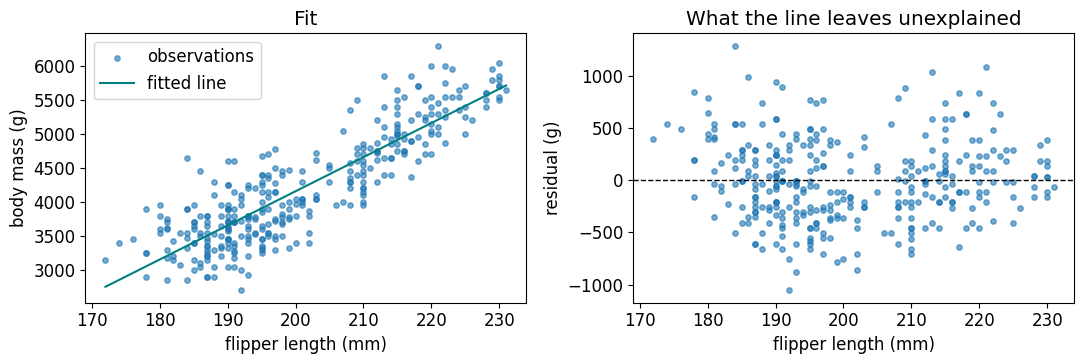

In [15]:
X = penguins[["flipper_length_mm"]]  # a table: one row per observation
y = penguins["body_mass_g"]

line = LinearRegression().fit(X, y)
prediction = line.predict(X)
residual = y - prediction
print(f"Slope = {line.coef_[0]:.2f} g/mm; intercept = {line.intercept_:.1f} g")

x_grid = pd.DataFrame({"flipper_length_mm": np.linspace(X.min().iloc[0], X.max().iloc[0], 200)})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(X.iloc[:, 0], y, s=15, alpha=0.6, label="observations")
axes[0].plot(x_grid.iloc[:, 0], line.predict(x_grid), color="teal", label="fitted line")
axes[0].set(xlabel="flipper length (mm)", ylabel="body mass (g)", title="Fit")
axes[0].legend()
axes[1].scatter(X.iloc[:, 0], residual, s=15, alpha=0.6)
axes[1].axhline(0, color="black", ls="--", lw=1)
axes[1].set(xlabel="flipper length (mm)", ylabel="residual (g)", title="What the line leaves unexplained")
plt.tight_layout()
plt.show()

> The line describes an association, not a causal effect. These observations mix three species: a pooled trend can hide differences between groups.

## 1.2 Fit a nonlinear curve with SciPy

**Which decay time describes these measurements?**

We define the model $f(t)=A e^{-t/\tau}+C$ and let `curve_fit` estimate its three parameters. `p0` supplies the starting values in the order **amplitude, decay time, offset**.

In [18]:
time = np.linspace(0, 5, 60)
response = 3 * np.exp(-time / 1.4) + 0.5 + rng.normal(0, 0.15, len(time))

def decay(t, amplitude, tau, offset):
    return amplitude * np.exp(-t / tau) + offset

start = [3.0, 1.0, 0.0]  # amplitude, decay time, offset
parameters, covariance = curve_fit(decay, time, response, p0=start, maxfev=5000)
amplitude, tau, offset = parameters
print(f"Amplitude = {amplitude:.3f}; decay time = {tau:.3f}; offset = {offset:.3f}")

Amplitude = 3.012; decay time = 1.518; offset = 0.435


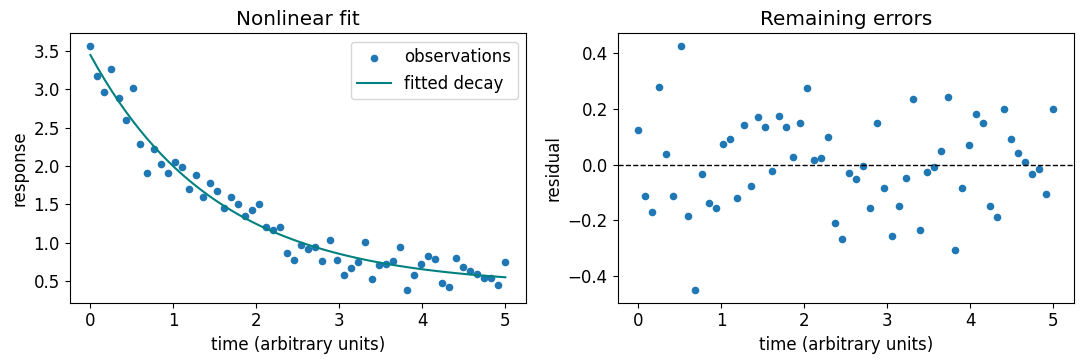

In [19]:
fitted_response = decay(time, *parameters)  # * unpacks the three fitted parameters
residual = response - fitted_response

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(time, response, s=20, label="observations")
axes[0].plot(time, fitted_response, color="teal", label="fitted decay")
axes[0].set(xlabel="time (arbitrary units)", ylabel="response", title="Nonlinear fit")
axes[0].legend()
axes[1].scatter(time, residual, s=20)
axes[1].axhline(0, color="black", ls="--", lw=1)
axes[1].set(xlabel="time (arbitrary units)", ylabel="residual", title="Remaining errors")
plt.tight_layout()
plt.show()

> SciPy searches for parameters; we supply the function and the observations. Convergence says the search stopped. It does not, by itself, establish that the model is adequate.

### 🔧 Your turn 1

Fit the flipper-length/body-mass line using **only Gentoo penguins**. Print its slope and intercept, and plot the observations with the fitted line. Does the slope match the pooled fit?

In [5]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 1</b> (click to expand)</summary>

```python
gentoo = penguins[penguins["species"] == "Gentoo"]
X_g = gentoo[["flipper_length_mm"]]
y_g = gentoo["body_mass_g"]
line_g = LinearRegression().fit(X_g, y_g)
print(f"Gentoo slope = {line_g.coef_[0]:.2f}; pooled slope = {line.coef_[0]:.2f} g/mm")
print(f"Gentoo intercept = {line_g.intercept_:.1f} g")

order = np.argsort(X_g.iloc[:, 0].to_numpy())
plt.figure(figsize=(7, 3.8))
plt.scatter(X_g.iloc[:, 0], y_g, s=20, label="Gentoo observations")
plt.plot(X_g.iloc[order, 0], line_g.predict(X_g.iloc[order]), color="teal", label="fitted line")
plt.xlabel("flipper length (mm)")
plt.ylabel("body mass (g)")
plt.legend()
plt.tight_layout()
plt.show()
```

The subset and the pooled sample answer different questions. Their fitted slopes need not agree.

</details>

---
# 2. Distribution fitting and checking

## 2.1 Fit a Normal distribution

**Can a Normal distribution describe body mass within one group?**

We select **male Gentoo penguins**, rather than mixing species and sexes. `stats.norm.fit` estimates the mean and standard deviation by maximum likelihood. We then create `dist`, a distribution object with those parameters.

n = 61; fitted mean = 5484.8 g; fitted SD = 310.6 g


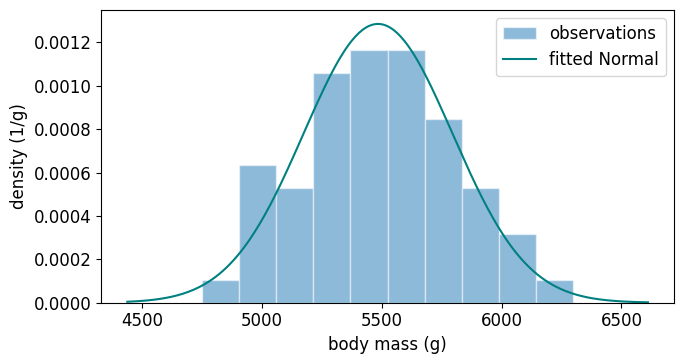

In [20]:
data = penguins.loc[
    (penguins["species"] == "Gentoo") & (penguins["sex"] == "MALE"), "body_mass_g"
].to_numpy()

mu, sigma = stats.norm.fit(data)
dist = stats.norm(loc=mu, scale=sigma)  # keep the fitted distribution as an object
print(f"n = {len(data)}; fitted mean = {mu:.1f} g; fitted SD = {sigma:.1f} g")

x = np.linspace(data.min() - sigma, data.max() + sigma, 300)
plt.figure(figsize=(7, 3.8))
plt.hist(data, bins=10, density=True, alpha=0.5, edgecolor="white", label="observations")
plt.plot(x, dist.pdf(x), color="teal", label="fitted Normal")
plt.xlabel("body mass (g)")
plt.ylabel("density (1/g)")
plt.legend()
plt.tight_layout()
plt.show()

## 2.2 One object, many useful methods

`dist` can evaluate a PDF or CDF, compute moments and entropy, and generate samples. These are properties of the **fitted model**, not a new description computed directly from the observations.

`stats(moments="sk")` returns skewness and **excess** kurtosis; for a Normal both are zero. `entropy()` returns differential entropy in nats.

In [21]:
skewness, excess_kurtosis = dist.stats(moments="sk")
new_sample = dist.rvs(size=200, random_state=rng)
print(f"Generated {len(new_sample)} values; their sample mean is {new_sample.mean():.1f} g")

pd.Series({
    "mean (g)": dist.mean(),
    "standard deviation (g)": dist.std(),
    "variance (g²)": dist.var(),
    "skewness": skewness,
    "excess kurtosis": excess_kurtosis,
    "differential entropy (nats)": dist.entropy(),
}).round(3)

Generated 200 values; their sample mean is 5480.8 g


,0
mean (g),5484.836
standard deviation (g),310.581
variance (g²),96460.629
skewness,0.000
excess kurtosis,0.000
differential entropy (nats),7.157


## 2.3 Check the fitted family with KS

**Is the gap between the sample CDF and the model CDF unusually large?**

KS measures the largest vertical gap, $D$. Because we fitted the parameters to these data, the comparison must repeat the fitting step. `goodness_of_fit` does that for us on simulated samples.

Use independent observations and a continuous distribution. Recorded masses are rounded, so this is an approximate continuous-data check. The CDF below uses the parameters returned by the check; for a Normal, SciPy uses the $n-1$ variance estimate internally.

KS distance D = 0.060; p-value = 0.834


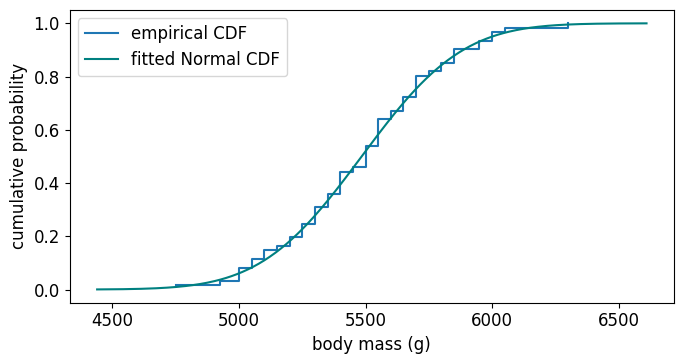

In [22]:
ks = stats.goodness_of_fit(stats.norm, data, statistic="ks", n_mc_samples=999, rng=rng)
checked_dist = stats.norm(*ks.fit_result.params)  # the parameters used by this check
print(f"KS distance D = {ks.statistic:.3f}; p-value = {ks.pvalue:.3f}")

sorted_data = np.sort(data)
ecdf = np.arange(1, len(data) + 1) / len(data)
plt.figure(figsize=(7, 3.8))
plt.step(sorted_data, ecdf, where="post", label="empirical CDF")
plt.plot(x, checked_dist.cdf(x), color="teal", label="fitted Normal CDF")
plt.xlabel("body mass (g)")
plt.ylabel("cumulative probability")
plt.legend()
plt.tight_layout()
plt.show()

> A small p-value is evidence against the Normal family for these data. A large p-value means we have not detected a mismatch; it does not prove the model is correct. The p-value here is estimated from repeated simulated samples.

---
# 3. Comparing groups

**Which comparison matches the observations we collected?**

| Data | Question | Test |
|------|----------|------|
| Two independent groups | Are the population means equal? | Welch's t-test |
| Three independent groups | Are all population means equal? | One-way ANOVA |
| The same subjects measured twice | Is the population mean change zero? | Paired t-test |

For the first two examples we compare **male penguins** across species. pandas selects the groups and shows their sizes, means and standard deviations.

In [23]:
males = penguins[penguins["sex"] == "MALE"]
species = ["Adelie", "Chinstrap", "Gentoo"]
groups = [males.loc[males["species"] == s, "body_mass_g"].to_numpy() for s in species]
adelie, chinstrap, gentoo_male = groups
males.groupby("species")["body_mass_g"].agg(["size", "mean", "std"]).round(1)

,size,mean,std
species,,,
Adelie,73,4043.5,346.8
Chinstrap,34,3939.0,362.1
Gentoo,61,5484.8,313.2


## 3.1 Two independent groups: Welch's t-test

**Are mean body masses equal for male Adelie and Chinstrap penguins?**

$H_0$: their population means are equal. Use independent observations and approximately Normal within-group errors, especially for small samples. Welch allows unequal variances: `equal_var=False`.

In [24]:
welch = stats.ttest_ind(adelie, chinstrap, equal_var=False)
print(f"Mean difference (Adelie − Chinstrap) = {adelie.mean() - chinstrap.mean():.1f} g")
print(f"Welch t = {welch.statistic:.3f}; p-value = {welch.pvalue:.3f}")

Mean difference (Adelie − Chinstrap) = 104.5 g
Welch t = 1.409; p-value = 0.164


> The mean difference gives its size in grams. The p-value asks how unusual the test statistic would be under equal population means. A large p-value does not establish equality.

## 3.2 Three independent groups: one-way ANOVA

**Are mean body masses equal across all three species?**

$H_0$: all three population means are equal. Classical ANOVA assumes independent observations, approximately Normal within-group errors and a common variance. The SDs above help us inspect the common-variance assumption.

ANOVA F = 370.396; p-value = 9.72e-62


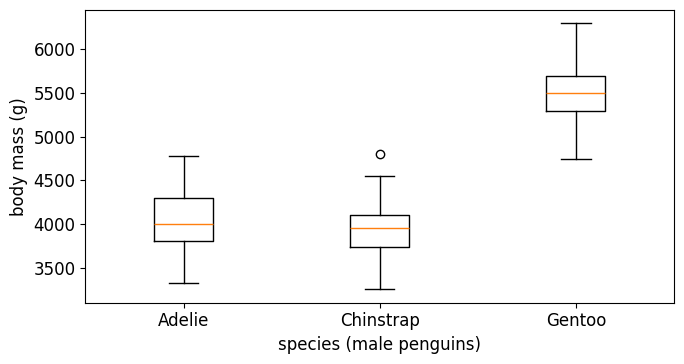

In [11]:
anova = stats.f_oneway(adelie, chinstrap, gentoo_male)
print(f"ANOVA F = {anova.statistic:.3f}; p-value = {anova.pvalue:.3g}")

plt.figure(figsize=(7, 3.8))
plt.boxplot(groups)
plt.xticks([1, 2, 3], species)
plt.xlabel("species (male penguins)")
plt.ylabel("body mass (g)")
plt.tight_layout()
plt.show()

> Rejection says **at least one** population mean differs. ANOVA alone does not identify which pairs differ.

## 3.3 Paired measurements: each subject's change

**Did scores change between the two measurements?**

This is a simulated study of 30 subjects. **Each row is one subject**, with a before and an after score. Keep that pairing when comparing the columns.

$H_0$: the population mean of `after − before` is zero. Subjects should be independent of one another; the differences should be approximately Normal.

In [12]:
before = rng.normal(10, 2, 30)
after = before + 0.6 + rng.normal(0, 0.8, 30)
paired = pd.DataFrame({"subject": np.arange(1, 31), "before": before, "after": after})
paired.head()

,subject,before,after
0,1,8.004215,8.117383
1,2,9.717114,10.195402
2,3,9.333675,10.384850
3,4,8.083223,9.471590
4,5,13.365422,13.527029


Mean change (after − before) = 0.370 points
Paired t = 2.800; p-value = 0.009


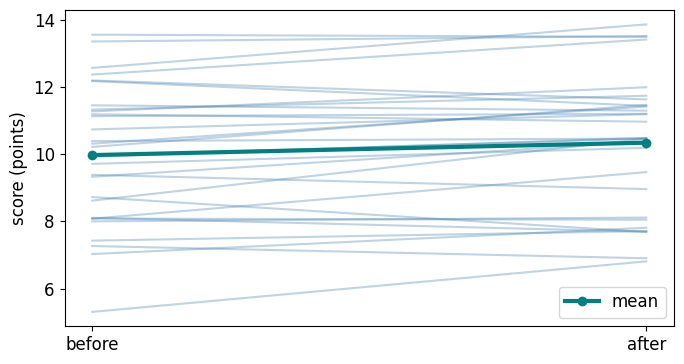

In [13]:
paired_test = stats.ttest_rel(paired["after"], paired["before"])
changes = paired["after"] - paired["before"]
print(f"Mean change (after − before) = {changes.mean():.3f} points")
print(f"Paired t = {paired_test.statistic:.3f}; p-value = {paired_test.pvalue:.3f}")

plt.figure(figsize=(7, 3.8))
plt.plot([0, 1], paired[["before", "after"]].to_numpy().T, color="steelblue", alpha=0.35)
plt.plot([0, 1], paired[["before", "after"]].mean(), "o-", color="teal", lw=3, label="mean")
plt.xticks([0, 1], ["before", "after"])
plt.ylabel("score (points)")
plt.legend()
plt.tight_layout()
plt.show()

> The paired test uses variation **across the subjects' changes**. Differences in their starting scores are not the uncertainty we want to measure.

### 🔧 Your turn 2

Compute one `after − before` difference per subject. Use `stats.ttest_1samp(changes, popmean=0)` to test their mean against zero. Compare its statistic and p-value with `ttest_rel` above. Why do they agree?

In [14]:
# Your code here

<details>
<summary><b>💡 Solution — Exercise 2</b> (click to expand)</summary>

```python
changes = paired["after"] - paired["before"]
one_sample = stats.ttest_1samp(changes, popmean=0)
print(f"One-sample t = {one_sample.statistic:.3f}; p-value = {one_sample.pvalue:.3f}")
print(f"Paired t     = {paired_test.statistic:.3f}; p-value = {paired_test.pvalue:.3f}")
```

A paired t-test is a one-sample t-test of the within-subject differences against zero.

</details>

---
# Wrap-up

## Which tool for which question

| Task | Tool |
|------|------|
| Fit a linear relation and predict | `LinearRegression().fit(X, y)`, `.predict(X)` |
| Fit a function you define | `curve_fit(function, x, y, p0=...)` |
| Estimate Normal parameters and keep the model | `stats.norm.fit(data)` → `stats.norm(loc=mu, scale=sigma)` |
| Use that distribution | `dist.pdf`, `.cdf`, `.mean`, `.var`, `.moment`, `.rvs`, `.entropy` |
| Check a fitted continuous family using KS | `stats.goodness_of_fit(family, data, statistic="ks")` |
| Compare two independent population means | `stats.ttest_ind(a, b, equal_var=False)` |
| Compare several independent population means | `stats.f_oneway(a, b, c)` |
| Test the mean change of paired observations | `stats.ttest_rel(after, before)` |
| Other class tools: category counts / two distributions | `stats.chisquare` or `stats.chi2_contingency` / `stats.ks_2samp` |

**Three habits:** plot the data and fit; state the question and assumptions; interpret the p-value together with the observed difference.

## Where to look things up

- SciPy distributions and tests: <https://docs.scipy.org/doc/scipy/reference/stats.html>
- SciPy curve fitting: <https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html>
- scikit-learn linear regression: <https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html>
- pandas: <https://pandas.pydata.org/docs/>

---